In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [4]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [5]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [6]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_eff096_notrueptcons.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [7]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [8]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [9]:
print(df_match.shape[0], df_allfake.shape[0])

2412535 1527396


In [10]:
print(np.unique(df_match['bs']))

[-1  1]


In [11]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [12]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [13]:
plt.rcParams['font.size'] = 12

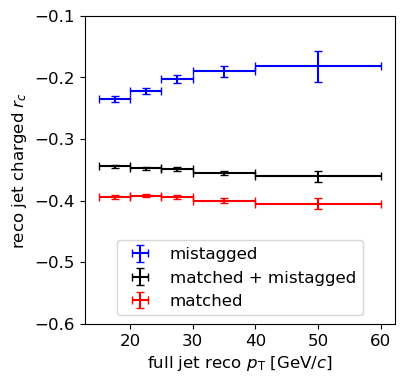

In [14]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [15]:
rc_allfake_bs_vs_pts_array

[-0.23480064044229704,
 -0.22249862197511672,
 -0.20273463185764512,
 -0.19022690168964218,
 -0.1824277369363831]

In [16]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [17]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [18]:
b_fake_array

[array([0.61740032, 0.38259968]),
 array([0.61124931, 0.38875069]),
 array([0.60136732, 0.39863268]),
 array([0.59511345, 0.40488655]),
 array([0.59121387, 0.40878613])]

In [19]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [20]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

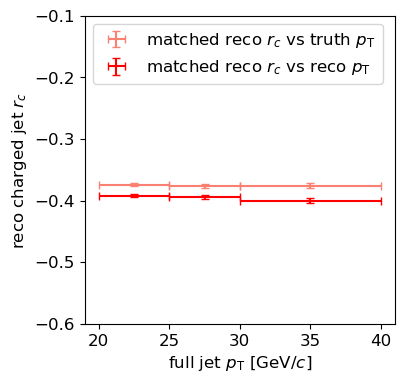

In [21]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [22]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69738536 0.30261464]
[0.69610788 0.30389212]
[0.69688784 0.30311216]
[0.70019599 0.29980401]
[0.70251322 0.29748678]


In [23]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2732452/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [24]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.31279235, 0.2604592 , 0.23332237, 0.2146003 , 0.1993737 ])

Process data

In [25]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [26]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [27]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [28]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [29]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [30]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [31]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[237769.73227232 116456.9491368 ]
[487.61637818 341.25789242]
1
[72379. 38554.]
[54717.85551643 27321.62400657]
[233.91848049 165.29254069]
2
[16450.  8688.]
[12922.82570842  6349.91657279]
[113.67860708  79.68636378]
3
[4758. 2573.]
[3821.74681184 1936.01839262]
[61.82027832 44.00020901]
4
[334. 153.]
[276.59609302 113.30891303]
[16.63117834 10.64466594]


In [32]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

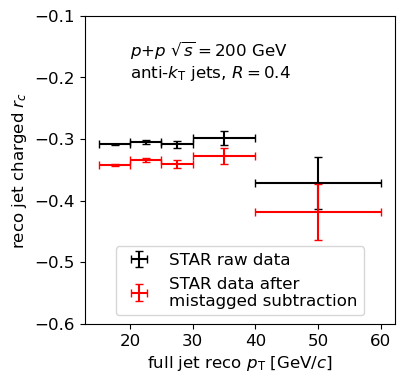

In [33]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [34]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [35]:
reweight_array

[array([0.96250385, 1.08641111]),
 array([0.95814143, 1.09588297]),
 array([0.9621684 , 1.08697897]),
 array([0.94795635, 1.12154859]),
 array([1.00979387, 0.97687183])]

([], [])

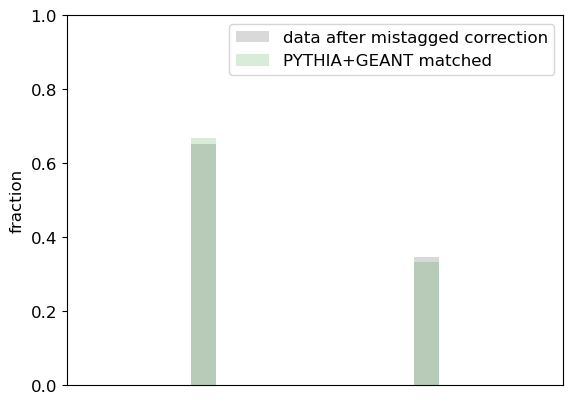

In [36]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [37]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.153276062896694
anomaly reco pT: 62.853705443277754
anomaly reco pT: 62.96298659444578
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.746029305931756
anomaly reco pT: 65.45530859825888
anomaly reco pT: 63.085829497123754
anomaly reco pT: 66.83963074901102
anomaly reco pT: 65.5495693388613
anomaly reco pT: 62.38132748663066
anomaly reco pT: 62.99359031776366
anomaly reco pT: 67.1333301990355
anomaly reco pT: 63.64818004148316
anomaly reco pT: 60.55736397596093
anomaly reco pT: 64

anomaly reco pT: 60.45025587004038
anomaly reco pT: 61.86694629679367
anomaly reco pT: 67.59938875022952
anomaly reco pT: 62.86606859698301
anomaly reco pT: 63.2210723798295
anomaly reco pT: 62.61099604338352
anomaly reco pT: 60.35238529674527
anomaly reco pT: 60.396526050380544
anomaly reco pT: 61.08133864736215
anomaly reco pT: 60.71513640529403
anomaly reco pT: 63.08584362374407
anomaly reco pT: 68.24831923111424
anomaly reco pT: 62.8181597276261
anomaly reco pT: 61.412439493673766
anomaly reco pT: 61.347736871062985
anomaly reco pT: 61.02147632892541
anomaly reco pT: 70.03649149954671
anomaly reco pT: 60.757687655694376
anomaly reco pT: 66.22961059676287
anomaly reco pT: 60.293464781197066
anomaly reco pT: 60.25965231087885
anomaly reco pT: 60.69135212323932
anomaly reco pT: 60.11974178663405
anomaly reco pT: 62.372927580141585
anomaly reco pT: 60.47297117299494
anomaly reco pT: 60.87052921361896
anomaly reco pT: 65.37212921820844
anomaly reco pT: 63.85124183763149
anomaly reco pT:

anomaly reco pT: 61.837073547266975
anomaly reco pT: 65.39807453498909
anomaly reco pT: 60.574141272547756
anomaly reco pT: 61.816918277994326
anomaly reco pT: 60.34577172692865
anomaly reco pT: 66.78466945932772
anomaly reco pT: 65.86804145154221
anomaly reco pT: 60.039992416227214
anomaly reco pT: 60.217385119456345
anomaly reco pT: 61.23079662193888
anomaly reco pT: 62.296368200663885
anomaly reco pT: 60.58564821822483
anomaly reco pT: 61.68059794731317
anomaly reco pT: 62.832636315781265
anomaly reco pT: 63.82654613577097
anomaly reco pT: 69.078424585103
anomaly reco pT: 64.21149177204236
anomaly reco pT: 65.37225443338379
anomaly reco pT: 62.139763620120824
anomaly reco pT: 61.798087886220436
anomaly reco pT: 60.48160954995578
anomaly reco pT: 67.18709477662233
anomaly reco pT: 60.09020994455192
anomaly reco pT: 61.619524213622306
anomaly reco pT: 63.31898904982115
anomaly reco pT: 60.07102500643125
anomaly reco pT: 62.08195655168501
anomaly reco pT: 63.149861630056094
anomaly rec

anomaly reco pT: 61.49052768720084
anomaly reco pT: 68.09959388111457
anomaly reco pT: 60.468610487613645
anomaly reco pT: 63.93180363140101
anomaly reco pT: 66.46104849005009
anomaly reco pT: 65.91597999800783
anomaly reco pT: 62.01106976992982
anomaly reco pT: 62.42202802458868
anomaly reco pT: 60.16047150617755
anomaly reco pT: 70.64250379062159
anomaly reco pT: 62.912793080628866
anomaly reco pT: 62.62036063826332
anomaly reco pT: 61.10476487708871
anomaly reco pT: 60.50659974179755
anomaly reco pT: 66.94727996267524
anomaly reco pT: 73.39946693221643
anomaly reco pT: 61.22578698730328
anomaly reco pT: 61.29062756689943
anomaly reco pT: 62.553255622557934
anomaly reco pT: 61.930048604173756
anomaly reco pT: 61.38677872346441
anomaly reco pT: 63.47305061763001
anomaly reco pT: 61.641088226629975
anomaly reco pT: 61.77018429862436
anomaly reco pT: 60.57106435333869
anomaly reco pT: 62.5219345419139
anomaly reco pT: 60.61298014218606
anomaly reco pT: 65.14922986425985
anomaly reco pT:

anomaly reco pT: 70.94475989279319
anomaly reco pT: 61.02452574971954
anomaly reco pT: 61.8920714536897
anomaly reco pT: 61.5131184376956
anomaly reco pT: 60.572207248392736
anomaly reco pT: 60.17442640811988
anomaly reco pT: 65.52085985663128
anomaly reco pT: 60.06011117703726
anomaly reco pT: 69.41891426749709
anomaly reco pT: 61.56141318339931
anomaly reco pT: 61.82866966390176
anomaly reco pT: 60.79391394146196
anomaly reco pT: 63.44584168696167
anomaly reco pT: 60.05724498304847
anomaly reco pT: 64.93741492529657
anomaly reco pT: 60.81330520834206
anomaly reco pT: 61.7961645052885
anomaly reco pT: 65.71729226850006
anomaly reco pT: 69.76373465662891
anomaly reco pT: 63.743163597286255
anomaly reco pT: 61.79103685180874
anomaly reco pT: 65.60260368695586
anomaly reco pT: 60.53151935897834
anomaly reco pT: 62.99651256623422
anomaly reco pT: 62.819668811200835
anomaly reco pT: 61.452905582931486
anomaly reco pT: 62.321086893556085
anomaly reco pT: 60.41934591709344
anomaly reco pT: 7

anomaly reco pT: 61.16319960004661
anomaly reco pT: 62.239882287151794
anomaly reco pT: 60.521746224625105
anomaly reco pT: 60.52914763423112
anomaly reco pT: 60.71562865466052
anomaly reco pT: 69.11736825506338
anomaly reco pT: 62.97565515894301
anomaly reco pT: 69.5142268875664
anomaly reco pT: 63.774924506260376
anomaly reco pT: 64.04077527411904
anomaly reco pT: 65.84552105613078
anomaly reco pT: 67.29790627455124
anomaly reco pT: 61.61412291688729
anomaly reco pT: 61.480555628321795
anomaly reco pT: 62.99505969229138
anomaly reco pT: 60.723222920459904
anomaly reco pT: 71.01868458502177
anomaly reco pT: 61.027749387158586
anomaly reco pT: 60.267100761302615
anomaly reco pT: 66.44668233355917
anomaly reco pT: 60.260942601705516
anomaly reco pT: 70.86250121653538
anomaly reco pT: 65.87964645176156
anomaly reco pT: 61.79199957702336
anomaly reco pT: 60.80116072274952
anomaly reco pT: 61.29109086638426
anomaly reco pT: 63.530619029638
anomaly reco pT: 63.32693347301722
anomaly reco pT

... (35 outputs left out)

anomaly reco pT: 61.67023088041911
anomaly reco pT: 62.30723469654345
anomaly reco pT: 73.73221254537091
anomaly reco pT: 62.37299863217058
anomaly reco pT: 72.91446337641423
anomaly reco pT: 64.91500836563613
anomaly reco pT: 60.932073649060634
anomaly reco pT: 60.01550935869139
anomaly reco pT: 62.312677425607326
anomaly reco pT: 60.536659652346465
anomaly reco pT: 63.39417680281562
anomaly reco pT: 64.59033517069085
anomaly reco pT: 60.77883639640974
anomaly reco pT: 61.59743184225914
anomaly reco pT: 62.12861800381819
anomaly reco pT: 67.94178311585942
anomaly reco pT: 60.63453721820577
anomaly reco pT: 63.44403644053514
anomaly reco pT: 60.640852377223815
anomaly reco pT: 61.15052196005195
anomaly reco pT: 61.320558796136325
anomaly reco pT: 62.90964663625422
anomaly reco pT: 61.48680049223194
anomaly reco pT: 60.474750604968186
anomaly reco pT: 70.84315464336441
anomaly reco pT: 61.92534586619952
anomaly reco pT: 64.61167983367942
anomaly reco pT: 62.91536082346625
anomaly reco p

anomaly reco pT: 62.32698069264111
anomaly reco pT: 63.63411845186029
anomaly reco pT: 60.00478994632899
anomaly reco pT: 63.403271181078914
anomaly reco pT: 61.08513187601476
anomaly reco pT: 62.53458542765311
anomaly reco pT: 61.9944279774964
anomaly reco pT: 62.01206968586356
anomaly reco pT: 60.09787078586106
anomaly reco pT: 60.48476719345234
anomaly reco pT: 63.52826778617119
anomaly reco pT: 62.32565679963697
anomaly reco pT: 62.43500761803754
anomaly reco pT: 60.40692758389495
anomaly reco pT: 62.9818641882484
anomaly reco pT: 63.31958476514284
anomaly reco pT: 61.96365584249061
anomaly reco pT: 60.23695838987487
anomaly reco pT: 71.60701002835559
anomaly reco pT: 62.396562268922175
anomaly reco pT: 61.5810083062782
anomaly reco pT: 68.53923997112858
anomaly reco pT: 61.09090956196156
anomaly reco pT: 63.23312395465088
anomaly reco pT: 63.20751116539416
anomaly reco pT: 61.09552947718905
anomaly reco pT: 61.17343047347276
anomaly reco pT: 61.98946986641298
anomaly reco pT: 60.4

anomaly reco pT: 62.1994543567997
anomaly reco pT: 62.072755225195145
anomaly reco pT: 68.01171539727342
anomaly reco pT: 62.185722171069855
anomaly reco pT: 61.0155207423607
anomaly reco pT: 61.66096513584184
anomaly reco pT: 62.72250015561953
anomaly reco pT: 60.84209105174485
anomaly reco pT: 60.88139350836386
anomaly reco pT: 62.27324868221418
anomaly reco pT: 67.50768458549679
anomaly reco pT: 65.62299859039155
anomaly reco pT: 62.67136030764501
anomaly reco pT: 62.32268438080635
anomaly reco pT: 61.04791375123212
anomaly reco pT: 61.257852574040356
anomaly reco pT: 63.387755672272014
anomaly reco pT: 61.07382260631102
anomaly reco pT: 80.04169508060383
anomaly reco pT: 66.47326198968055
anomaly reco pT: 61.01695798641532
anomaly reco pT: 60.25820175971781
anomaly reco pT: 61.02253372051367
anomaly reco pT: 61.15457802087321
anomaly reco pT: 67.73360765782255
anomaly reco pT: 62.116761442306796
anomaly reco pT: 66.95646909192942
anomaly reco pT: 62.56054850143328
anomaly reco pT: 

/tmp/ipykernel_2732452/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [38]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [39]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [40]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

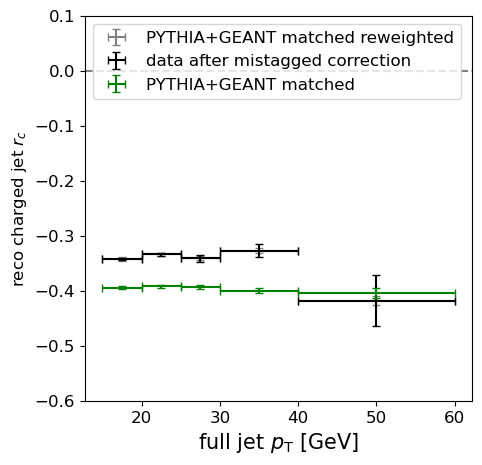

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [41]:
print(rc_match_bs_vs_pts_array_rw)

[-0.34247217813332886, -0.3339396065032773, -0.3410469065431719, -0.32751047537910577, -0.4187870826294959]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

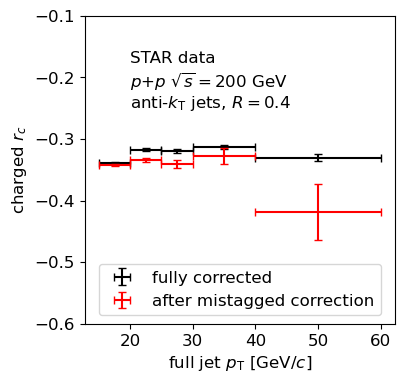

In [42]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

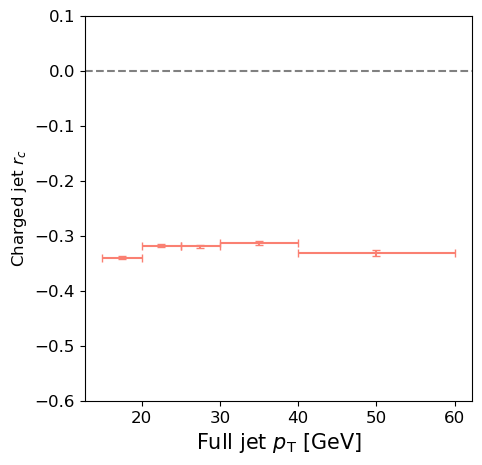

In [43]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [44]:
rc_match_bs_vs_pt_array

[-0.3397437289480048,
 -0.3177811564600664,
 -0.3191365800826993,
 -0.3128544027710918,
 -0.33063584199277196]

In [45]:
rc_err_match_bs_vs_pt_array

[0.0028468147402237083,
 0.0023729926860749594,
 0.002934518785461275,
 0.0036485189538367014,
 0.005408433581126812]